# Jeux globaux — la sélection d'équilibre par le bruit privé

*Carnet 11f de la série GameTheory — prolonge 11 (jeux bayésiens) et 10 (induction en avant).*

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [Index](README.md)

Un jeu de **coordination** possède, à information complète, plusieurs équilibres : rien dans les payoffs ne désigne celui qui sera joué. Les **jeux globaux** (Carlsson et van Damme, 1993) lèvent cette indétermination en perturbant l'information : l'état de l'économie n'est pas observé exactement, mais à travers un **signal privé bruité**. Deux résultats en découlent, et ce carnet les mesure :

1. les calculs étudient une **stratégie de coupure symétrique** ;
2. quand le bruit s'éteint, cette coupure converge vers l'équilibre **risque-dominant** au sens de Harsanyi et Selten — et non vers l'équilibre Pareto-dominant, avec lequel il entre en conflit sur une moitié de la bande de multiplicité.

C'est une sélection obtenue par la **croyance**, non par le temps. L'induction en avant du carnet 10 opère l'autre sélection, le long de l'arbre : là, chaque nœud est visité et la crédibilité tranche ; ici, tout est simultané et seule la finesse du signal tranche.

**Plan.** §1 le jeu et sa multiplicité · §2 la perturbation · §3 la coupure mesurée · §4 ce que la limite sélectionne, mesuré · §5 la sélection sous coordination perturbée, mesurée · §6 le raccourci qui ne marche pas · §7 exercices.
**Version jumelle** : [Python](GameTheory-11f-Jeux-Globaux-Selection-Equilibre-Python.ipynb). Source primaire : carnet Python versionné ; bibliographie héritée sans nouvelle lecture revendiquée. MathNet.Numerics 5.0.0 utilise un générateur différent de NumPy : les tirages ne sont pas bit à bit identiques.


## 1. Le jeu — une complémentarité stratégique

Deux joueurs (`i = 1, 2`) choisissent **simultanément** d'**investir** (`I`) ou de s'**abstenir** (`N`). L'état `θ` est le rendement fondamental de l'investissement. Investir coûte `c`, rapporte `θ`, et procure en plus un bonus `γ` **si l'autre investit aussi** :

$$
u_i(I, I) = \theta - c + \gamma, \qquad u_i(I, N) = \theta - c, \qquad u_i(N, \cdot) = 0
$$

Le terme `γ` est la **complémentarité stratégique** : investir vaut davantage quand l'autre investit. C'est lui, et lui seul, qui crée la multiplicité — sans lui, chacun décide seul de son côté, l'investissement est dominé ou dominant selon `θ`, et il n'y a rien à sélectionner.

À information complète (`θ` connu de tous), on vérifie chaque équilibre par **déviation** : `(I, I)` tient si dévier vers `N` ne paie pas, c'est-à-dire si `u(I, I) >= u(N, I) = 0` ; `(N, N)` tient si `u(N, N) = 0 >= u(I, N)`.

In [1]:
#r "nuget: MathNet.Numerics,5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using MathNet.Numerics.Distributions;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
record Svg(string Content);
Formatter.Register<Svg>((plot, writer) => writer.Write(plot.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
// MU et SIGMA_T décrivent le prior commun ; C est le coût et GAMMA la complémentarité.
const double MU = .8, SIGMA_T = .5, C = 1.0, GAMMA = .6;
// Le bonus n'est perçu que si les deux joueurs investissent.
double Payoff(bool invest, bool autre, double theta) => invest ? theta - C + (autre ? GAMMA : 0) : 0;
Console.WriteLine($"mu={MU}, sigma_theta={SIGMA_T}, c={C}, gamma={GAMMA}, bande=[{C-GAMMA:F2},{C:F2}]");
foreach (double theta in new[] { .2, .4, .6, .8, 1.0, 1.3 })
{
    double both = Payoff(true, true, theta);
    double alone = Payoff(true, false, theta);
    Console.WriteLine($"theta={theta:F2}, u(I,I)={both:F2}, u(I,N)={alone:F2}, (I,I)={both>=0}, (N,N)={alone<=0}");
}


Installed Packages MathNet.Numerics, 5.0.0

mu=0.8, sigma_theta=0.5, c=1, gamma=0.6, bande=[0.40,1.00]


theta=0.20, u(I,I)=-0.20, u(I,N)=-0.80, (I,I)=False, (N,N)=True


theta=0.40, u(I,I)=0.00, u(I,N)=-0.60, (I,I)=True, (N,N)=True


theta=0.60, u(I,I)=0.20, u(I,N)=-0.40, (I,I)=True, (N,N)=True


theta=0.80, u(I,I)=0.40, u(I,N)=-0.20, (I,I)=True, (N,N)=True


theta=1.00, u(I,I)=0.60, u(I,N)=0.00, (I,I)=True, (N,N)=True


theta=1.30, u(I,I)=0.90, u(I,N)=0.30, (I,I)=True, (N,N)=False


### Lecture du résultat

Trois régimes, séparés par deux seuils :

| `θ` | équilibres purs | pourquoi |
|---|---|---|
| `θ < c - γ` | `(N, N)` seul | investir perd même si l'autre investit (`u(I, I) < 0`) : `I` est **dominée** |
| `c - γ ≤ θ ≤ c` | **`(I, I)` et `(N, N)`** | chacun veut investir si l'autre investit, et s'abstenir sinon : **deux** équilibres purs |
| `θ > c` | `(I, I)` seul | investir gagne même si l'autre s'abstient (`u(I, N) > 0`) : `I` est **dominante** |

La bande du milieu est le problème. Sa largeur vaut exactement `γ = 0.60`, et à l'intérieur la théorie est muette : rien, dans les payoffs, ne hiérarchise `(I, I)` et `(N, N)`. Aux deux bornes un équilibre devient faible — `(I, I)` en `θ = c - γ`, `(N, N)` en `θ = c` — ce qui est la signature d'un changement de régime et non d'une indétermination.

Toute la question des jeux globaux tient en une phrase : **que devient cette bande quand les joueurs cessent de connaître `θ` exactement ?**

Dans l’intérieur de la bande, il existe aussi un équilibre mixte : ce tableau ne recense que les deux accords purs.


## 2. La perturbation — un état commun, des signaux privés

`θ` n'est plus connu : c'est un tirage, et **chaque joueur en reçoit un signal bruité** :

$$
\theta \sim \mathcal{N}(\mu, \sigma_\theta^2), \qquad x_i = \theta + \sigma_\varepsilon \, \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, 1) \ \text{i.i.d.}
$$

Le bruit est **privé** : il est indépendant d'un joueur à l'autre. Chacun sait que l'autre détient *un* signal, mais pas lequel. C'est précisément cet angle mort qui fait le travail de sélection.

Vu son signal, le joueur met à jour sa croyance sur `θ` — une moyenne pondérée de l'a priori et du signal :

$$
\lambda = \frac{\sigma_\theta^2}{\sigma_\theta^2 + \sigma_\varepsilon^2}, \qquad
\mathbb{E}[\theta \mid x_i] = \mu + \lambda (x_i - \mu), \qquad
\mathrm{Var}(\theta \mid x_i) = \frac{\sigma_\theta^2 \sigma_\varepsilon^2}{\sigma_\theta^2 + \sigma_\varepsilon^2}
$$

`λ` est la **précision relative** du signal : `λ → 1` quand le bruit s'éteint, `λ → 0` quand il noie l'information.

In [2]:
// Posterior gaussien : les précisions du prior et du signal se combinent.
(double Lambda, double Variance) Coefficients(double sigma)
{
    double st2 = SIGMA_T * SIGMA_T,
        se2 = sigma * sigma;
    return (st2 / (st2 + se2), st2 * se2 / (st2 + se2));
}
double EsperanceEtat(double x, double sigma) => MU + Coefficients(sigma).Lambda * (x - MU);
foreach (double s in new[] { 1.0, .5, .3, .1, .02, .001 })
{
    var (lambda, variance) = Coefficients(s);
    Console.WriteLine(
        $"sigma={s:F3}, lambda={lambda:F6}, variance={variance:F6}, écart-type={Math.Sqrt(variance):F6}"
    );
}

// Les 400000 couples sont générés par MathNet avec une graine fixe.
var rng = new Random(21932);
int selected = 0;
double total = 0;
for (int i = 0; i < 400000; i++)
{
    double theta = Normal.Sample(rng, MU, SIGMA_T);
    double signal = theta + Normal.Sample(rng, 0, .3);
    // La fenêtre sélectionne les états compatibles avec un signal voisin de 1, pas les états voisins de 1.
    if (Math.Abs(signal - 1.0) < .02)
    {
        selected++;
        total += theta;
    }
}
Console.WriteLine(
    $"Monte-Carlo x≈1 : moyenne={total / selected:F5}, n={selected}, formule={EsperanceEtat(1, .3):F5}"
);


sigma=1.000, lambda=0.200000, variance=0.200000, écart-type=0.447214


sigma=0.500, lambda=0.500000, variance=0.125000, écart-type=0.353553


sigma=0.300, lambda=0.735294, variance=0.066176, écart-type=0.257248


sigma=0.100, lambda=0.961538, variance=0.009615, écart-type=0.098058


sigma=0.020, lambda=0.998403, variance=0.000399, écart-type=0.019984


sigma=0.001, lambda=0.999996, variance=0.000001, écart-type=0.001000


Monte-Carlo x≈1 : moyenne=0.94760, n=10413, formule=0.94706


### Lecture du résultat

Quand le bruit passe de `1,0` à `0,001`, le poids du signal `λ` augmente de `0,200` à `0,999996`, tandis que la variance conditionnelle passe de `0,200` à environ `0,000001`. Pour `λ=0,2`, le signal très bruité reçoit un poids faible face au prior.

Le contrôle Monte-Carlo conserve `10 413` des `400 000` couples `(θ,x)` dans la fenêtre `x=1±0,02`. Dans cette exécution MathNet, la moyenne retenue vaut `0,94760`, contre `0,94706` pour la formule conditionnelle : un écart d'environ `0,00054`. L'écart-type conditionnel vaut `0,257248`, soit environ `0,00252` pour l'erreur type d'une moyenne de cette taille. Les réalisations NumPy et MathNet diffèrent ; le contrôle compare dans chaque langue ses propres tirages à la même formule gaussienne.


## 3. Une coupure symétrique

On cherche un équilibre **symétrique en stratégie de coupure** : chaque joueur investit si et seulement si son signal dépasse un seuil `c*`. Un tel équilibre tient dans une seule équation — l'indifférence **au seuil**.

Au signal `c*`, investir et s'abstenir doivent rapporter la même chose :

$$
\underbrace{\mathbb{E}[\theta \mid c^*]}_{\text{rendement fondamental attendu}} - c + \gamma \underbrace{\mathbb{P}(x_j \geq c^* \mid x_i = c^*)}_{p} = 0
$$

Reste à calculer `p`. Sachant `x_i`, le signal de l'autre est normal, centré sur la **même** espérance `E[θ | x_i]`, avec la variance `Var(θ | x_i) + σ_ε²` — l'incertitude sur l'état **plus** le bruit propre de l'autre :

$$
p = \Phi\!\left( \frac{\mathbb{E}[\theta \mid c^*] - c^*}{\sqrt{\mathrm{Var}(\theta \mid c^*) + \sigma_\varepsilon^2}} \right) = \Phi(w),
\qquad
w = -\frac{(1 - \lambda)(c^* - \mu)}{\sqrt{\mathrm{Var}(\theta \mid c^*) + \sigma_\varepsilon^2}}
$$

Pour deux joueurs, `p` est une croyance sur l'action adverse. Dans un continuum, les signaux sont indépendants conditionnellement à `θ`, et la fraction réalisée dépend de `θ` ; conditionnellement au seul signal propre, une incertitude sur cette fraction subsiste. Les lectures sont donc distinctes.

Deux remarques qui portent tout le résultat :

- quand `σ_ε → 0`, on a `w → 0`, donc `p → Φ(0) = 1/2` : au seuil, un joueur croit que l'autre investit **une fois sur deux** ;
- l'équation se réduit alors à `c* - c + γ/2 = 0`, soit `c* = c - γ/2` — le **milieu** de la bande de multiplicité, et non l'un de ses bords.

In [3]:
// L'incertitude sur theta est ajoutée au bruit du signal adverse.
double Phi(double z) => Normal.CDF(0, 1, z);
double ProbaAutre(double cutoff, double sigma)
{
    var (lambda, variance) = Coefficients(sigma);
    // Le joueur marginal observe cutoff : on conditionne theta sur ce signal précis.
    double posterior = MU + lambda * (cutoff - MU);
    return Phi((posterior - cutoff) / Math.Sqrt(variance + sigma * sigma));
}
double EcartIndifference(double x, double sigma) =>
    EsperanceEtat(x, sigma) - C + GAMMA * ProbaAutre(x, sigma);
double Coupure(double sigma, double lo = -20, double hi = 20, double tol = 1e-13)
{
    // Le changement de signe est vérifié avant la bissection, sans supposer une racine dans toute fenêtre.
    if (!(EcartIndifference(lo, sigma) < 0 && EcartIndifference(hi, sigma) > 0))
        throw new ArgumentException("Racine non encadrée");
    for (int i = 0; i < 300; i++)
    {
        double mid = (lo + hi) / 2,
            value = EcartIndifference(mid, sigma);
        // Résidu et largeur bornent deux sources distinctes d’arrêt numérique.
        if (Math.Abs(value) < tol || hi - lo < tol)
            return mid;
        if (value < 0)
            lo = mid;
        else
            hi = mid;
    }
    return (lo + hi) / 2;
}
double seuilRisque = C - GAMMA / 2;
Console.WriteLine($"Seuil risque={seuilRisque:F4}, seuil Pareto={C - GAMMA:F4}");
foreach (double s in new[] { 1.0, .5, .3, .2, .1, .05, .02, .01, .001 })
{
    double k = Coupure(s);
    Console.WriteLine(
        $"sigma={s:F3}, c*={k:F7}, écart={k - seuilRisque:E3}, P(autre)={ProbaAutre(k, s):F6}"
    );
}


Seuil risque=0.7000, seuil Pareto=0.4000


sigma=1.000, c*=-0.8632668, écart=-1.563E+000, P(autre)=0.887756


sigma=0.500, c*=0.4740985, écart=-2.259E-001, P(autre)=0.604918


sigma=0.300, c*=0.6261851, écart=-7.381E-002, P(autre)=0.546342


sigma=0.200, c*=0.6650814, écart=-3.492E-002, P(autre)=0.527182


sigma=0.100, c*=0.6883698, écart=-1.163E-002, P(autre)=0.512228


sigma=0.050, c*=0.6954522, écart=-4.548E-003, P(autre)=0.505854


sigma=0.020, c*=0.6984646, écart=-1.535E-003, P(autre)=0.502289


sigma=0.010, c*=0.6992780, écart=-7.220E-004, P(autre)=0.501136


sigma=0.001, c*=0.6999319, écart=-6.815E-005, P(autre)=0.500113


### Lecture du résultat

La dernière colonne est la clé. À mesure que le bruit s'éteint, la probabilité que le joueur **au seuil** attribue à l'investissement de l'autre tend vers `0.5` — elle vaut `0.5001` à `σ_ε = 0.001` — et la coupure vient buter sur `c - γ/2 = 0.7000` : à `σ_ε = 0.001` l'écart tombe à `6.8e-05`.

Deux choses sont acquises à ce stade :

- pour **chaque** niveau de bruit affiché, la bissection trouve une racine ; les contrôles de grille et d'itération ne prouvent pas l'unicité globale ni l'absence d'équilibres hors de cette classe ;
- la limite `c - γ/2` n'est pas un bord de la bande mais son **milieu** : la sélection a donc un contenu précis, que le §4 identifie.

Le sens économique du résultat se lit sur la première ligne : plus le bruit est fort (`σ_ε = 1.0`), plus la coupure descend (`c* = -0.86`). Une coupure de signal plus basse rend la règle plus permissive ; elle ne signifie pas que le joueur exige un fondamental plus favorable.

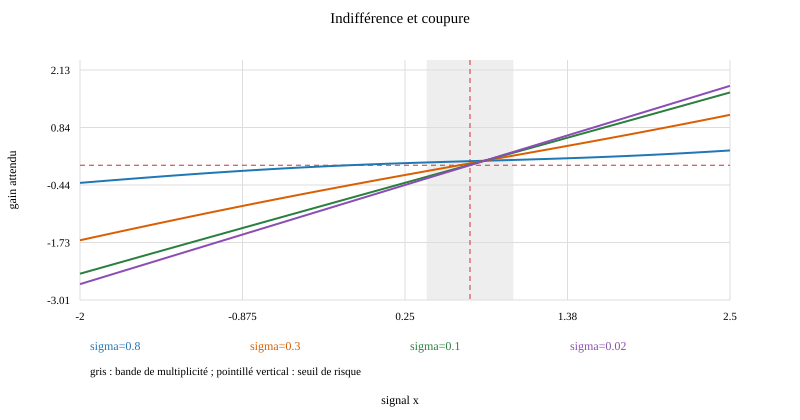

In [4]:
// SVG multisérie : axes, légende et bande de multiplicité sont tracés explicitement.
string Chart(
    double[] xs,
    List<(string Label, double[] Values, string Color)> series,
    string title,
    string xlabel,
    string ylabel,
    bool logX = false,
    double? vertical = null,
    double? horizontal = null,
    bool bandX = false,
    bool bandY = false
)
{
    // Seules les coordonnées du tracé deviennent logarithmiques ; les valeurs affichées restent en unités de sigma.
    var xx = logX ? xs.Select(Math.Log10).ToArray() : xs;
    double xmin = xx.Min(),
        xmax = xx.Max();
    double ymin = series.Min(s => s.Values.Min()),
        ymax = series.Max(s => s.Values.Max());
    // La référence horizontale participe aux bornes pour ne pas disparaître hors du cadre.
    if (horizontal.HasValue)
    {
        ymin = Math.Min(ymin, horizontal.Value);
        ymax = Math.Max(ymax, horizontal.Value);
    }
    double pad = Math.Max(.05, (ymax - ymin) * .08);
    ymin -= pad;
    ymax += pad;
    // Y est inversé parce que les coordonnées SVG croissent vers le bas.
    double X(double v) => 80 + (v - xmin) / (xmax - xmin) * 650;
    double Y(double v) => 300 - (v - ymin) / (ymax - ymin) * 230;
    var sb = new StringBuilder(
        $"<svg xmlns='http://www.w3.org/2000/svg' width='800' height='420'>"
        + $"<rect width='100%' height='100%' fill='white'/>"
        + $"<text x='400' y='23' text-anchor='middle' font-size='15'>{title}</text>"
        + $"<text x='400' y='404' text-anchor='middle'>{xlabel}</text>"
        + $"<text transform='translate(16,180) rotate(-90)' text-anchor='middle'>{ylabel}</text>"
    );
    // La même bande de multiplicité se projette sur x ou y selon la grandeur représentée.
    if (bandX)
        sb.Append(
            $"<rect x='{X(C - GAMMA):F2}' y='60' width='{X(C) - X(C - GAMMA):F2}' height='240' fill='#eee'/>"
        );
    if (bandY)
    {
        sb.Append(
            $"<rect x='80' y='{Y(C):F2}' width='650' height='{Y(C - GAMMA) - Y(C):F2}' fill='#eee'/>"
        );
        sb.Append(
            $"<line x1='80' y1='{Y(C - GAMMA):F2}' x2='730' y2='{Y(C - GAMMA):F2}' stroke='#27823d' stroke-dasharray='2 4'/>"
        );
        sb.Append(
            $"<text x='575' y='{Y(C - GAMMA) - 6:F2}' fill='#27823d' font-size='11'>Pareto = {C - GAMMA:F2}</text>"
        );
    }
    // En échelle logarithmique, les graduations reconvertissent la position en valeur de bruit.
    for (int i = 0; i <= 4; i++)
    {
        double a = xmin + (xmax - xmin) * i / 4,
            b = ymin + (ymax - ymin) * i / 4;
        sb.Append(
            $"<line x1='{X(a):F2}' y1='60' x2='{X(a):F2}' y2='300' stroke='#ddd'/><text x='{X(a):F2}' y='320' text-anchor='middle' font-size='11'>{(logX ? Math.Pow(10, a) : a):G3}</text>"
        );
        sb.Append(
            $"<line x1='80' y1='{Y(b):F2}' x2='730' y2='{Y(b):F2}' stroke='#ddd'/><text x='70' y='{Y(b) + 4:F2}' text-anchor='end' font-size='11'>{b:F2}</text>"
        );
    }
    if (vertical.HasValue)
        sb.Append(
            $"<line x1='{X(logX ? Math.Log10(vertical.Value) : vertical.Value):F2}' y1='60' "
            + $"x2='{X(logX ? Math.Log10(vertical.Value) : vertical.Value):F2}' y2='300' stroke='#c33' stroke-dasharray='5 4'/>"
        );
    if (horizontal.HasValue)
    {
        sb.Append(
            $"<line x1='80' y1='{Y(horizontal.Value):F2}' x2='730' y2='{Y(horizontal.Value):F2}' stroke='#c33' stroke-dasharray='5 4'/>"
        );
        if (bandY)
            sb.Append(
                $"<text x='575' y='{Y(horizontal.Value) - 6:F2}' fill='#c33' font-size='11'>risque = {horizontal.Value:F2}</text>"
            );
    }
    // Les indices communs alignent chaque ordonnée avec son abscisse, sans rééchantillonner les courbes.
    foreach (var item in series)
    {
        string points = string.Join(" ", xx.Select((x, i) => $"{X(x):F2},{Y(item.Values[i]):F2}"));
        sb.Append(
            $"<polyline points='{points}' fill='none' stroke='{item.Color}' stroke-width='2'/>"
        );
    }
    for (int i = 0; i < series.Count; i++)
        sb.Append(
            $"<text x='{90 + i * 160}' y='350' fill='{series[i].Color}' font-size='12'>{series[i].Label}</text>"
        );
    if (bandX)
        sb.Append(
            "<text x='90' y='375' font-size='11'>gris : bande de multiplicité ; pointillé vertical : seuil de risque</text>"
        );
    return sb.Append("</svg>").ToString();
}
var grid400 = Enumerable.Range(0, 400).Select(i => -2 + 4.5 * i / 399).ToArray();
var chartSeries = new List<(string, double[], string)>();
var palette = new[] { "#1f77b4", "#d95f02", "#2a7f3f", "#8b4db3" };
var chartSigmas = new[] { .8, .3, .1, .02 };
for (int i = 0; i < chartSigmas.Length; i++)
{
    double s = chartSigmas[i];
    chartSeries.Add(
        ($"sigma={s}", grid400.Select(x => EcartIndifference(x, s)).ToArray(), palette[i])
    );
}
display(
    new Svg(
        Chart(
            grid400,
            chartSeries,
            "Indifférence et coupure",
            "signal x",
            "gain attendu",
            false,
            seuilRisque,
            0,
            true
        )
    )
);


### Lecture du résultat

Sur la fenêtre et la grille tracées, chaque courbe montre une traversée de zéro, et le point de traversée se déplace vers `c - γ/2` à mesure que le bruit diminue. Ces tracés ne prouvent ni l'unicité en dehors de la fenêtre, ni l'absence d'équilibres hors de la classe des coupures.

Le trait vertical tombe à l'intérieur de la bande grisée : la sélection ne consiste pas à retenir un bord, mais un point **intérieur**. C'est ce point que la section suivante nomme.

In [5]:
// Meilleure réponse à un seuil adverse fixé, distincte de l'indifférence symétrique.
double? MeilleureReponse(
    double other,
    double sigma,
    double lo = -20,
    double hi = 20,
    double tol = 1e-13
)
{
    var (lambda, variance) = Coefficients(sigma);
    double Ecart(double x)
    {
        // Le posterior dépend du signal propre x ; seul le seuil adverse other entre dans sa probabilité d’investissement.
        double posterior = MU + lambda * (x - MU);
        return posterior
            - C
            + GAMMA * Phi((posterior - other) / Math.Sqrt(variance + sigma * sigma));
    }
    if (!(Ecart(lo) < 0 && Ecart(hi) > 0))
        return null;
    for (int i = 0; i < 300; i++)
    {
        double mid = (lo + hi) / 2,
            value = Ecart(mid);
        if (Math.Abs(value) < tol || hi - lo < tol)
            return mid;
        if (value < 0)
            lo = mid;
        else
            hi = mid;
    }
    return (lo + hi) / 2;
}
var auditGrid = Enumerable.Range(0, 161).Select(i => -8 + i * .1).ToArray();
foreach (double s in new[] { .8, .3, .1, .02 })
{
    var v = auditGrid.Select(x => EcartIndifference(x, s)).ToArray();
    Console.WriteLine(
        $"sigma={s:F3}, croissance sur 161 points={Enumerable.Range(1, v.Length - 1).All(i => v[i] > v[i - 1])}"
    );
}

// Quatre départs × quatre bruits, au plus 500 itérations chacun.
foreach (double s in new[] { .8, .3, .1, .02 })
{
    var endpoints = new List<double>();
    foreach (double start in new[] { -3.0, 0, 1, 2.5 })
    {
        double x = start;
        for (int step = 0; step < 500; step++)
        {
            var next = MeilleureReponse(x, s);
            // Une réponse absente interrompt cette trajectoire plutôt que d’inventer une coupure.
            if (next == null)
            {
                x = double.NaN;
                break;
            }
            if (Math.Abs(next.Value - x) < 1e-14)
            {
                x = next.Value;
                break;
            }
            x = next.Value;
        }
        endpoints.Add(x);
    }
    Console.WriteLine(
        $"sigma={s:F3} : {string.Join(", ", endpoints.Select(x => x.ToString("F7")))} ; étendue={endpoints.Max() - endpoints.Min():E2}"
    );
}


sigma=0.800, croissance sur 161 points=True


sigma=0.300, croissance sur 161 points=True


sigma=0.100, croissance sur 161 points=True


sigma=0.020, croissance sur 161 points=True


sigma=0.800 : -0.1353085, -0.1353085, -0.1353085, -0.1353085 ; étendue=5.68E-013


sigma=0.300 : 0.6261851, 0.6261851, 0.6261851, 0.6261851 ; étendue=1.42E-013


sigma=0.100 : 0.6883698, 0.6883698, 0.6883698, 0.6883698 ; étendue=1.42E-013


sigma=0.020 : 0.6984646, 0.6984646, 0.6984646, 0.6984646 ; étendue=4.26E-013


### Lecture du résultat

Deux contrôles numériques complémentaires :

- les valeurs de la condition d'indifférence sont **strictement croissantes sur la grille** de `[-8, 8]` à chaque niveau de bruit : cette grille n'établit pas sa monotonie entre les points ni hors de la fenêtre ;
- l'itération de la meilleure réponse, lancée depuis quatre points de départ éloignés (`-3`, `0`, `1`, `2.5`), aboutit au **même** point fixe, l'écart entre les trajectoires tombant à `1e-13`. Un point fixe supplémentaire pourrait être non attractif ou hors de la fenêtre.

C'est une mesure, pas la preuve de Carlsson et van Damme : leur résultat passe par l'**élimination itérée des stratégies dominées**, sous les hypothèses du théorème cité. Le carnet ne démontre pas l'unicité globale de la coupure ni l'absence d'autres classes d'équilibres.

### Exercices : pratiques progressives

Les trois exercices reprennent, dans l'ordre, les trois mécanismes du carnet : l'équation d'indifférence, le critère de sélection et les points fixes mesurés. Les cellules ci-dessous sont des squelettes — elles s'exécutent sans erreur et renvoient `null` tant qu'elles ne sont pas complétées.

**Exercice 1 — résoudre l'équation d'indifférence.** Implémenter `coupureEquilibre` par bissection, en réutilisant `EcartIndifference`, et vérifier que la valeur obtenue pour `sigma_eps = 0.05` reproduit celle du tableau du §3.

In [6]:
// Exercice 1 : obtenir une racine de l'indifférence.
Func<double, double?> coupureEquilibre = sigma =>
{
    // TODO : bissection de EcartIndifference.
    return null;
};
var cases1 = new[] { .05, .3, .8 };
var answers1 = cases1.Select(coupureEquilibre).ToArray();
if (answers1.All(x => x == null))
    Console.WriteLine("Exercice 1 à compléter");
else
{
    // Une réponse sur une partie des bruits ne valide pas le contrat commun aux trois cas.
    for (int i = 0; i < cases1.Length; i++)
        if (
            answers1[i] == null
            || !double.IsFinite(answers1[i].Value)
            || Math.Abs(EcartIndifference(answers1[i].Value, cases1[i])) > 1e-9
        )
            throw new Exception("Racine incorrecte ou réponse partielle");
    Console.WriteLine("Exercice 1 : coupures vérifiées");
}


Exercice 1 à compléter


## 4. Ce que la limite sélectionne — la dominance du risque

La limite `c - γ/2` n'est pas une constante trouvée au hasard numérique : c'est le seuil qui sépare les deux équilibres selon le critère de **Harsanyi et Selten**. Pour un jeu 2×2 à deux équilibres stricts, on compare les **produits de Nash** : pour chaque équilibre, le produit des pertes qu'encourrait chaque joueur en changeant unilatéralement d’action. L'équilibre au produit le plus élevé est **risque-dominant** — dans ce jeu symétrique, la comparaison revient à évaluer les actions face à une croyance adverse uniforme.

Sur ce jeu, les pertes à la déviation valent :

| équilibre | payoff | déviation | perte | produit |
|---|---|---|---|---|
| `(I, I)` | `θ - c + γ` | `N` rapporte `0` | `θ - c + γ` | `(θ - c + γ)²` |
| `(N, N)` | `0` | `I` rapporte `θ - c` | `c - θ` | `(c - θ)²` |

`(I, I)` est donc risque-dominant dès que `θ - c + γ ≥ c - θ`, c'est-à-dire **`θ ≥ c - γ/2`**. Exactement la limite mesurée au §3. La limite de la branche mesurée coïncide avec ce seuil de dominance du risque ; ce calcul ne démontre pas l'unicité globale.

C'est ici que les deux critères entrent en conflit. L'équilibre **Pareto-dominant** est `(I, I)` dès que `θ > c - γ` : sur la moitié basse de la bande, `c - γ < θ < c - γ/2`, `(I, I)` est le meilleur pour les deux joueurs — et c'est pourtant `(N, N)` que la dominance du risque retient, ce qui coïncide avec la limite de la branche de coupures calculée. Aux bornes, il faut distinguer indifférence de Pareto et égalité de dominance de risque.

In [7]:
// Les produits des pertes à la déviation comparent les deux accords.
(double II, double NN) Produits(double theta) =>
    ((theta - C + GAMMA) * (theta - C + GAMMA), (C - theta) * (C - theta));
foreach (double theta in new[] { .4, .5, .6, .7, .8, .9, 1.0 })
{
    var (ii, nn) = Produits(theta);
    Console.WriteLine(
        $"theta={theta:F2}, produit II={ii:F6}, produit NN={nn:F6}, risque={(Math.Abs(ii - nn) < 1e-12 ? "égalité" : ii > nn ? "II" : "NN")}"
    );
}
// La recherche reste dans la bande où les deux accords sont des équilibres de Nash.
double lo = C - GAMMA,
    hi = C;
for (int i = 0; i < 200; i++)
{
    double mid = (lo + hi) / 2;
    var (ii, nn) = Produits(mid);
    if (ii > nn)
        hi = mid;
    else
        lo = mid;
}
double seuilNash = (lo + hi) / 2;
Console.WriteLine(
    $"Seuil risque={seuilNash:F10}, formule={seuilRisque:F10}, coupure sigma=.001={Coupure(.001):F7}, seuil Pareto={C - GAMMA:F4}"
);


theta=0.40, produit II=0.000000, produit NN=0.360000, risque=NN


theta=0.50, produit II=0.010000, produit NN=0.250000, risque=NN


theta=0.60, produit II=0.040000, produit NN=0.160000, risque=NN


theta=0.70, produit II=0.090000, produit NN=0.090000, risque=égalité


theta=0.80, produit II=0.160000, produit NN=0.040000, risque=II


theta=0.90, produit II=0.250000, produit NN=0.010000, risque=II


theta=1.00, produit II=0.360000, produit NN=0.000000, risque=II


Seuil risque=0.7000000000, formule=0.7000000000, coupure sigma=.001=0.6999319, seuil Pareto=0.4000


### Lecture du résultat

Trois nombres se répondent, et c'est tout l'argument du carnet :

- le seuil de dominance du risque, calculé **indépendamment** sur les produits de Nash : `0.7000000000` ;
- la limite de la coupure d'équilibre, obtenue **par résolution numérique** du jeu à signaux : `0.6999319` à `σ_ε = 0.001`, soit `6.8e-05` du précédent ;
- le seuil de dominance Pareto, `0.4000`, qui n'est **pas** la limite.

Deux procédures sans rapport — une comparaison de produits de pertes sur une matrice 2×2, et une bissection sur une équation de croyance — tombent sur le même point. La coïncidence n'est pas un hasard : c'est le théorème de Carlsson et van Damme, et ce carnet en vérifie l'arithmétique sur un jeu concret.

Sur la table, la bascule se lit entre `0.60` et `0.80`, avec l'égalité exacte en `0.70` : en dessous, `(N, N)` est risque-dominant alors que `(I, I)` rapporte davantage aux deux joueurs ; au-dessus, les deux critères s'accordent.

**Exercice 2 — confronter les deux critères.** Écrire `conflit(c, gamma)` qui renvoie l'intervalle `(c - gamma, c - gamma/2)` dont les bornes délimitent le conflit strict entre Pareto et risque ; les bornes correspondent aux égalités et sont exclues du conflit strict. Vérifier que sa largeur vaut `gamma/2`, puis expliquer en commentaire quel seuil est rejoint par la branche à petit bruit et pourquoi ces deux frontières du jeu complet ne dépendent pas de `sigma_theta`. La fonction renvoie les deux bornes ; elle ne les déclare pas membres du conflit strict.

In [8]:
// Exercice 2 : intervalle entre les critères de Pareto et de risque.
Func<double, double, (double Low, double High)?> conflit = (cout, gamma) =>
{
    // TODO : renvoyer les deux bornes.
    return null;
};
// Les coûts et complémentarités varient ensemble pour éviter une réponse ajustée au seul exemple initial.
var cases2 = new[] { (C, GAMMA), (2.0, .8), (.5, .2) };
var answers2 = cases2.Select(x => conflit(x.Item1, x.Item2)).ToArray();
if (answers2.All(x => x == null))
    Console.WriteLine("Exercice 2 à compléter");
else
{
    for (int i = 0; i < cases2.Length; i++)
    {
        var (cout, gamma) = cases2[i];
        var x = answers2[i];
        if (
            x == null
            || !double.IsFinite(x.Value.Low)
            || !double.IsFinite(x.Value.High)
            || Math.Abs(x.Value.Low - (cout - gamma)) > 1e-10
            || Math.Abs(x.Value.High - (cout - gamma / 2)) > 1e-10
        )
            throw new Exception("Intervalle incorrect ou réponse partielle");
    }
    Console.WriteLine("Exercice 2 : intervalles vérifiés");
}


Exercice 2 à compléter


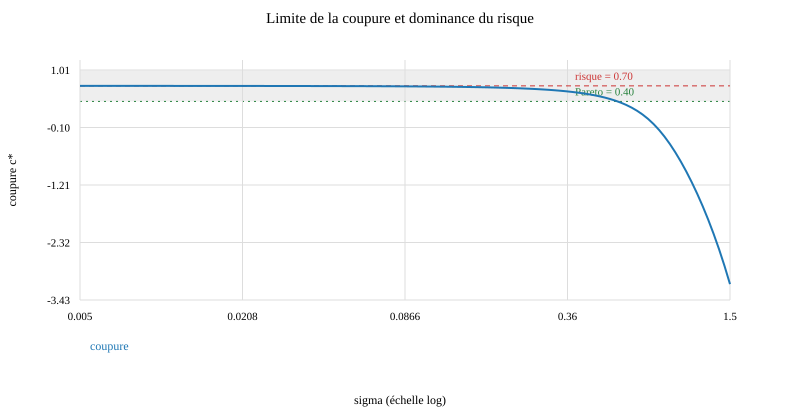

In [9]:
// 120 valeurs géométriques couvrent tout l'intervalle de bruit jusqu'à 1,5.
var bruits = Enumerable.Range(0, 120).Select(i => .005 * Math.Pow(1.5 / .005, i / 119.0)).ToArray();
var curve = bruits.Select(s => Coupure(s)).ToArray();
var series17 = new List<(string, double[], string)> { ("coupure", curve, "#1f77b4") };
display(
    new Svg(
        Chart(
            bruits,
            series17,
            "Limite de la coupure et dominance du risque",
            "sigma (échelle log)",
            "coupure c*",
            true,
            null,
            seuilRisque,
            false,
            true
        )
    )
);


### Lecture du résultat

À droite, le bruit est fort : la coupure s'effondre très en dessous de la bande — une coupure plus basse rend la règle en signal plus permissive, sans impliquer un fondamental plus favorable. En allant vers la gauche, le bruit s'éteint et la courbe se stabilise exactement sur le trait rouge de la dominance du risque, à l'intérieur de la bande grisée, **sans jamais rejoindre** le trait vert de la dominance Pareto.

C'est la réponse à la question du §1. La courbe décrit une branche de coupures : les mesures ne démontrent pas qu'elle épuise tous les équilibres, et sa limite se rapproche du milieu de la bande. La sélection tient donc à la structure de l'information, non à un raffinement des payoffs — les payoffs, eux, n'ont pas changé d'un iota entre le §1 et ici.

## 5. La sélection, mesurée sous coordination perturbée

Les sections 3 et 4 ont mesuré une branche **statique** : la coupure `c*` se déplace vers `c - γ/2` à mesure que le bruit privé s'éteint, et à la limite elle rejoint le seuil de dominance du risque. Ce résultat porte sur **l'équilibre** — sur ce qui existe — jamais sur le **chemin** qui y mène.

Savoir quel équilibre existe et savoir si l'on y arrive sont deux questions distinctes. Une sélection *affirmée* n'est pas une sélection *mesurée* : il manque l'observation d'un ensemble de trajectoires dont on regarde où elles se terminent.

### Ce qui perturbe la coordination

Dans un jeu de complémentarité, l'histoire d'un équilibre est faite de croyances partagées. La perturbation la plus directe n'est donc pas un choc sur les gains, mais **l'état initial de ces croyances** : ici, le taux `π₀` de la population qui investit au premier tour.

Trois issues sont possibles, et elles ne se distinguent qu'à la mesure :

| Ce qu'on observe | Ce que cela veut dire |
|---|---|
| toutes les valeurs de `π₀` mènent au même équilibre | la sélection est **nette** — le bruit privé a effacé l'histoire |
| deux valeurs de `π₀` mènent près de deux extrêmes différents | la sélection est **partielle** — deux bassins coexistent, l'histoire décide |
| aucune trajectoire ne se fixe près d'un extrême | il n'y a **aucune sélection** à observer |

### La dynamique retenue

Chaque joueur observe le taux agrégé `π` du tour précédent, forme `E[θ | x_i]`, et investit si l'écart anticipé reste positif compte tenu de `π` :

$$\text{investit} \iff \hat\theta_i - c + \gamma\,\pi \ge 0$$

Le seuil de signal correspondant est `x*(π) = μ + (c - γπ - μ)/λ`, d'où le taux induit au tour suivant :

$$F(\pi) = \Phi\!\left(\frac{\theta - x^*(\pi)}{\sigma_\varepsilon}\right)$$

Les équilibres de cette dynamique sont les **points fixes de `F`**. `F` est croissante : quand plus de gens investissent, chacun investit plus volontiers. Ici F est continue et croissante. Après le premier pas, une trajectoire d’itération est monotone et bornée ; elle converge donc, et la continuité fait de sa limite un point fixe. Le point atteint peut dépendre du départ. C'est exactement ce que la perturbation de coordination met à l'épreuve.

> **Ce que cette dynamique est, et ce qu'elle n'est pas.** C'est une meilleure réponse sur le taux *agrégé* — un raisonnement de niveau `k`, pas l'équilibre bayésien de Nash du §3. Le tableau suivant juxtapose une fraction inconditionnelle et une dynamique évaluée à `θ=μ` ; il compare deux objets distincts, sans démontrer une identité ou une non-identité générale des équilibres.

In [10]:
// Cette dynamique agrégée est distincte du BNE à coupure calculé plus haut.
double TauxInduit(double pi, double theta, double sigma)
{
    double lambda = Coefficients(sigma).Lambda;
    // pi est une croyance agrégée sur l’investissement adverse, et non la coupure symétrique du BNE.
    double xstar = MU + (C - GAMMA * pi - MU) / lambda;
    return Phi((theta - xstar) / sigma);
}
List<double> Trajectoire(
    double theta,
    double sigma,
    double pi0,
    int maxIter = 500,
    double tol = 1e-13
)
{
    var values = new List<double> { pi0 };
    for (int i = 0; i < maxIter; i++)
    {
        values.Add(TauxInduit(values.Last(), theta, sigma));
        // L’écart de deux taux successifs mesure ici l’arrêt d’une dynamique, pas une preuve d’unicité.
        if (Math.Abs(values[^1] - values[^2]) < tol)
            break;
    }
    return values;
}
var starts = new[] { .05, .25, .5, .75, .95 };
var bruitsDynamique = new[] { .6, .1, .01 };
foreach (double theta in new[] { .55, .85 })
foreach (double s in bruitsDynamique)
{
    var ends = starts.Select(x => Trajectoire(theta, s, x).Last()).ToArray();
    Console.WriteLine(
        $"theta={theta:F2}, sigma={s:F2}, coupure={Coupure(s):F6}, F(0)={TauxInduit(0, theta, s):F4}, F(1)={TauxInduit(1, theta, s):F4}, fins=[{string.Join(", ", ends.Select(x => x.ToString("F4")))}]"
    );
}


theta=0.55, sigma=0.60, coupure=0.337658, F(0)=0.1093, F(1)=0.8869, fins=[0.3957, 0.3957, 0.3957, 0.3957, 0.3957]


theta=0.55, sigma=0.10, coupure=0.688370, F(0)=0.0000, F(1)=0.9515, fins=[0.0000, 0.0000, 0.0000, 0.0000, 0.0000]


theta=0.55, sigma=0.01, coupure=0.699278, F(0)=0.0000, F(1)=1.0000, fins=[0.0000, 0.0000, 0.0000, 0.0000, 1.0000]


theta=0.85, sigma=0.60, coupure=0.337658, F(0)=0.2327, F(1)=0.9564, fins=[0.9415, 0.9415, 0.9415, 0.9415, 0.9415]


theta=0.85, sigma=0.10, coupure=0.688370, F(0)=0.0571, F(1)=1.0000, fins=[1.0000, 1.0000, 1.0000, 1.0000, 1.0000]


theta=0.85, sigma=0.01, coupure=0.699278, F(0)=0.0000, F(1)=1.0000, fins=[0.0000, 1.0000, 1.0000, 1.0000, 1.0000]


### Lecture du résultat

Les colonnes suivantes décrivent les mesures : `F(0)` et `F(1)`. Un point extrême exact serait fixe si et seulement si `F` **le fixe** — `F(0) = 0` pour `(N,N)`, `F(1) = 1` pour `(I,I)`.

| `σ_ε` | `θ = 0.55` | `θ = 0.85` | ce que la dynamique peut faire |
|---|---|---|---|
| `0.60` | `F(0) = 0.109`, `F(1) = 0.887` | `F(0) = 0.233`, `F(1) = 0.956` | aucun extrême n'est proche d'un point fixe à l'arrondi affiché |
| `0.10` | `F(0) = 0.000`, `F(1) = 0.952` | `F(0) = 0.057`, `F(1) = 1.000` | un extrême est proche d'un point fixe à l'arrondi affiché |
| `0.01` | `F(0) = 0.000`, `F(1) = 1.000` | `F(0) = 0.000`, `F(1) = 1.000` | deux extrêmes paraissent fixes à l'arrondi affiché |

Trois régimes, et ils ne se lisent pas dans `θ` seul :

- **Bruit fort (`0.60`)** — `F` reste loin de ses deux extrémités. Les cinq valeurs de `π₀` convergent vers le **même** point fixe, mais ce point est **intérieur** : `0.3957` à `θ = 0.55`, `0.9415` à `θ = 0.85`. Une fraction seulement de la population investit. Ce n'est pas une sélection entre deux équilibres purs — c'est l'absence d'équilibre pur.
- **Bruit intermédiaire (`0.10`)** — l'extrémité opposée au risque-dominant a cessé d'être un point fixe (`F(0) = 0.057 > 0` à `θ = 0.85` ; `F(1) = 0.952 < 1` à `θ = 0.55`), et les cinq départs calculés convergent vers un taux proche du profil pur risque-dominant : `(N,N)` à `θ = 0.55`, sous le seuil `c - γ/2 = 0.7` ; `(I,I)` à `θ = 0.85`, au-dessus. Une sélection **nette**, du côté prédit par la dominance du risque.
- **Bruit faible (`0.01`)** — `F(0) = 0` **et** `F(1) = 1` : les deux extrêmes apparaissent comme points fixes à l'arrondi, et les départs mesurés se répartissent en deux bassins : c'est une **bistabilité observée** sur ces trajectoires. Une seule valeur de `π₀` échappe au risque-dominant — `0.95` à `θ = 0.55`, `0.05` à `θ = 0.85` — et finit de l'autre côté.

Le résultat est un renversement, et c'est le point de la section : **c'est quand le bruit privé s'éteint que le passé redevient déterminant.** À bruit fort, tout converge au même endroit, mais cet endroit n'est plus un équilibre pur — l'unicité ne sélectionne donc rien entre deux équilibres. À bruit faible, deux catégories proches des extrêmes cohabitent et `π₀` tranche. La sélection est nette **entre** les deux, à bruit intermédiaire — sur les cinq départs étudiés, qui aboutissent au même taux terminal.
Les mots « pur » et les catégories de ce tableau correspondent aux arrondis et tolérances numériques. Pour un bruit gaussien fini, les probabilités théoriques sont strictement entre 0 et 1, même si le flottant peut s'arrondir aux extrêmes.


In [11]:
// pi3 est inconditionnel, tandis que F est évaluée à theta=MU : diagnostic de deux objets distincts.
foreach (double s in new[] { .8, .5, .3, .2, .1, .05, .02, .01 })
{
    double k = Coupure(s),
        pi3 = Phi((MU - k) / Math.Sqrt(SIGMA_T * SIGMA_T + s * s)),
        f = TauxInduit(pi3, MU, s);
    Console.WriteLine(
        $"sigma={s:F2}, c*={k:F6}, pi3={pi3:F4}, F(pi3)={f:F4}, différence={f - pi3:F4}"
    );
}


sigma=0.80, c*=-0.135308, pi3=0.8393, F(pi3)=0.9116, différence=0.0724


sigma=0.50, c*=0.474098, pi3=0.6776, F(pi3)=0.7956, différence=0.1181


sigma=0.30, c*=0.626185, pi3=0.6172, F(pi3)=0.7800, différence=0.1628


sigma=0.20, c*=0.665081, pi3=0.5989, F(pi3)=0.8223, différence=0.2234


sigma=0.10, c*=0.688370, pi3=0.5866, F(pi3)=0.9430, différence=0.3564


sigma=0.05, c*=0.695452, pi3=0.5824, F(pi3)=0.9987, différence=0.4163


sigma=0.02, c*=0.698465, pi3=0.5804, F(pi3)=1.0000, différence=0.4196


sigma=0.01, c*=0.699278, pi3=0.5798, F(pi3)=1.0000, différence=0.4202


### Lecture du résultat

La dernière colonne juxtapose une fraction inconditionnelle `π₃` et `F` évaluée pour `θ=μ` : ce sont deux objets distincts, et leur écart ne prouve pas à lui seul une identité ou une non-identité générale des équilibres.

- `π₃` reste entre `0.58` et `0.84` quand le bruit décroît de `0.80` à `0.01` — il ne s'approche jamais de `1/2` ;
- `F(π₃) - π₃` est **positif partout**, et grandit jusqu'à `0.42` quand le bruit s'éteint.

Autrement dit, dans ce diagnostic, `F(π₃)` est supérieur à `π₃` aux points affichés. La coupure du §3 vient de l’indifférence bayésienne symétrique ; F décrit une réponse agrégée à état fixé. La juxtaposition présente ne suffit pas à ordonner leurs équilibres sur une même population.

L'écart ne se referme pas quand `σ_ε → 0`, et c'est le point le plus utile de cette cellule : la limite `c - γ/2` est un résultat sur la **coupure**, et elle ne se transporte pas telle quelle sur la **fraction agrégée**. Il faut distinguer une croyance conditionnelle du joueur, une fraction conditionnelle à l'état et une fraction inconditionnelle.

> **Conséquence de lecture.** La suite mesure la sélection sur la dynamique agrégée, celle qu'on peut simuler et observer. Ses verdicts portent donc sur *cette* dynamique et ne valent pas comme confirmation numérique de la coupure du §3. Le carnet gagne ici une distinction qu'il n'avait pas : l'unicité de l'équilibre bayésien et la convergence d'une dynamique de coordination sont deux propriétés distinctes.

In [12]:
// Population finie : 200 signaux par graine, puis au plus 200 réponses agrégées.
(bool Converged, double Final) Simulation(
    double theta,
    double sigma,
    int seed,
    double initial,
    int maxTours = 200,
    double tol = 1e-12
)
{
    var rng = new Random(seed);
    double lambda = Coefficients(sigma).Lambda;
    // Les signaux sont tirés une fois : les tours suivants réagissent à une population fixe.
    var signals = Enumerable
        .Range(0, 200)
        .Select(_ => theta + Normal.Sample(rng, 0, sigma))
        .ToArray();
    // Chaque agent combine son signal avec le même prior avant de répondre au taux courant.
    var estimated = signals.Select(x => MU + lambda * (x - MU)).ToArray();
    double pi = initial;
    for (int t = 0; t < maxTours; t++)
    {
        double next = estimated.Count(x => x - C + GAMMA * pi >= 0) / 200.0;
        if (Math.Abs(next - pi) < tol)
            return (true, next);
        pi = next;
    }
    // Le budget épuisé conserve le dernier taux et annonce explicitement la non-convergence.
    return (false, pi);
}
string Classer(double pi, double eps = .02) =>
    pi >= 1 - eps ? "II"
    : pi <= eps ? "NN"
    : "intérieur";
var seeds = new[] { 0, 1, 7, 42 };
int totalTrajectories = 0;
foreach (double theta in new[] { .55, .85 })
foreach (double s in bruitsDynamique)
{
    var finals = new List<double>();
    int failed = 0;
    foreach (int seed in seeds)
    foreach (double start in starts)
    {
        var result = Simulation(theta, s, seed, start);
        finals.Add(result.Final);
        if (!result.Converged)
            failed++;
        totalTrajectories++;
    }
    // II et NN désignent les voisinages des deux accords ; les autres taux restent classés intérieurs.
    var groups = finals.GroupBy(x => Classer(x)).ToDictionary(g => g.Key, g => g.Count());
    Console.WriteLine(
        $"theta={theta:F2}, sigma={s:F2} : II={groups.GetValueOrDefault("II")}, NN={groups.GetValueOrDefault("NN")}, "
            + $"intérieur={groups.GetValueOrDefault("intérieur")}, min={finals.Min():F3}, max={finals.Max():F3}, non convergé={failed}/{finals.Count}"
    );
}
Console.WriteLine(
    $"Trajectoires simulées : {totalTrajectories} (4 graines × 5 départs × 2 theta × 3 bruits)."
);


theta=0.55, sigma=0.60 : II=0, NN=0, intérieur=20, min=0.155, max=0.850, non convergé=0/20


theta=0.55, sigma=0.10 : II=0, NN=20, intérieur=0, min=0.000, max=0.000, non convergé=0/20


theta=0.55, sigma=0.01 : II=4, NN=16, intérieur=0, min=0.000, max=1.000, non convergé=0/20


theta=0.85, sigma=0.60 : II=0, NN=0, intérieur=20, min=0.915, max=0.965, non convergé=0/20


theta=0.85, sigma=0.10 : II=20, NN=0, intérieur=0, min=1.000, max=1.000, non convergé=0/20


theta=0.85, sigma=0.01 : II=16, NN=4, intérieur=0, min=0.000, max=1.000, non convergé=0/20


Trajectoires simulées : 120 (4 graines × 5 départs × 2 theta × 3 bruits).


### Lecture du résultat

Le Monte-Carlo ajoute une mesure de **dispersion**. Les catégories proches de 0 et 1 utilisent une tolérance de 0,02 ; pour un bruit gaussien fini, la CDF théorique est strictement entre 0 et 1, même si l'arithmétique peut arrondir à ces extrêmes.

| `θ` | `σ_ε` | issue dominante | verdict |
|---|---|---|---|
| `0.55` | `0.60` | 20/20 intérieur, `π` de `0.155` à `0.850` | aucune sélection |
| `0.55` | `0.10` | 20/20 `(N,N)` | sélection nette |
| `0.55` | `0.01` | 16/20 `(N,N)`, 4/20 `(I,I)` | sélection partielle |
| `0.85` | `0.60` | 20/20 intérieur, `π` de `0.915` à `0.965` | aucune sélection |
| `0.85` | `0.10` | 20/20 `(I,I)` | sélection nette |
| `0.85` | `0.01` | 16/20 `(I,I)`, 4/20 `(N,N)` | sélection partielle |

Trois choses que seule la population finie montre :

1. **Les départs mesurés favorisent le profil risque-dominant.** À `σ_ε = 0.01`, le rapport est de **16 contre 4** dans les deux sens : les quatre graines et cinq départs donnent quatre trajectoires sur cinq près du profil risque-dominant. Une sélection forte, pas une sélection absolue. Le champ moyen annonçait le même 4/5 par le compte des points de départ (un seul `π₀` sur cinq bascule) — deux calculs complémentaires, même répartition sur les départs testés.
2. **La dispersion à bruit fort est énorme.** À `θ = 0.55`, `σ_ε = 0.60`, le taux terminal va de `0.155` à `0.850` selon la graine et le point de départ. Le champ moyen donnait **un** point fixe à `0.3957` ; la population finie en admet une plage, parce que la meilleure réponse y est un **escalier** : ses marches plates coupent la diagonale plusieurs fois, et `π₀` choisit la marche.
3. **La réalisation dépend du générateur.** Dans les quatre graines MathNet utilisées ici, les vingt trajectoires à `θ=0.85`, `σ=0.10` sont classées proches de `(I,I)` ; les échantillons NumPy du jumeau donnent une réalisation différente. Ce sont des diagnostics conditionnels aux graines, pas une fréquence universelle.

La réponse honnête à la question de départ tient en trois lignes : sur ces graines et ces départs, les taux terminaux dépendent du bruit, de l'échantillon et du départ. Le bruit privé décide du *régime* ; le point de départ et l'échantillon décident du sort *à l'intérieur* du régime. Aucune des deux mesures ne permet d'annoncer un équilibre terminal sans dire d'où l'on part.

## 6. Le raccourci qui ne marche pas

L'équation d'indifférence du §3 s'écrit souvent, dans les présentations rapides, sous une forme close :

$$
c^* = c - \gamma \, p, \qquad p = \mathbb{P}(x_j \geq c^* \mid x_i = c^*)
$$

C'est une **erreur**, et une erreur instructive. Cette relation exige `E[θ | c*] = c*`, soit `(1-λ)(μ-c*)=0` : elle traite le joueur au seuil comme s'il **connaissait** `θ`. Or `λ < 1` tant que le bruit privé existe, et `E[θ | c*] = μ + λ(c* - μ)` s'écarte de `c*` d'autant plus que le signal est peu informatif. L’égalité peut tenir si `λ=1` ou dans le cas particulier `c*=μ`. Pour les paramètres de ce carnet, la coupure diffère de μ et le raccourci ne devient exact qu’à la limite du bruit nul.

La cellule suivante mesure l'écart entre les deux relations.

In [13]:
// Le raccourci néglige l'écart entre signal et espérance conditionnelle.
foreach (double s in new[] { 1.0, .5, .3, .2, .1, .05, .01, .001 })
{
    double cutoff = Coupure(s),
        probability = ProbaAutre(cutoff, s),
        naive = C - GAMMA * probability;
    Console.WriteLine(
        $"sigma={s:F3}, c*={cutoff:F7}, p={probability:F6}, raccourci={naive:F7}, écart={naive - cutoff:E2}"
    );
}


sigma=1.000, c*=-0.8632668, p=0.887756, raccourci=0.4673466, écart=1.33E+000


sigma=0.500, c*=0.4740985, p=0.604918, raccourci=0.6370492, écart=1.63E-001


sigma=0.300, c*=0.6261851, p=0.546342, raccourci=0.6721949, écart=4.60E-002


sigma=0.200, c*=0.6650814, p=0.527182, raccourci=0.6836909, écart=1.86E-002


sigma=0.100, c*=0.6883698, p=0.512228, raccourci=0.6926633, écart=4.29E-003


sigma=0.050, c*=0.6954522, p=0.505854, raccourci=0.6964874, écart=1.04E-003


sigma=0.010, c*=0.6992780, p=0.501136, raccourci=0.6993183, écart=4.03E-005


sigma=0.001, c*=0.6999319, p=0.500113, raccourci=0.6999323, écart=4.00E-007


### Lecture du résultat

Pour les paramètres de ce carnet, l’écart du raccourci diminue lorsque le bruit décroît :

- à `σ_ε = 1.0`, il se trompe de `+1.33` — plus que la largeur entière de la bande ;
- à `σ_ε = 0.5`, encore de `+0.163`, soit un quart de cette largeur ;
- à `σ_ε = 0.001`, l'écart est de `4.0e-07` : le bruit est devenu négligeable, `λ ≈ 1`, et la forme close rejoint la vraie.

Autrement dit, l'erreur n'est pas une faute de calcul mais une **hypothèse implicite** : la forme close suppose résolue la question que le carnet pose. C'est pourquoi le §3 garde l'espérance conditionnelle `E[θ | c*]` dans l'équation plutôt que de la remplacer par `c*`.

**Exercice 3 — étudier l'itération depuis plusieurs départs.** Écrire une fonction qui, partant d'un seuil arbitraire, itère `MeilleureReponse` jusqu'au point fixe. L'appliquer à quatre départs éloignés pour deux niveaux de bruit, et vérifier que l'écart entre les points d'arrivée est de l'ordre de `1e-13`. Conclure sur les départs mesurés et expliquer pourquoi ils ne prouvent pas le nombre global de points fixes.

In [14]:
// Exercice 3 : itérer la meilleure réponse depuis un départ donné.
Func<double, double, int, double, double?> pointFixe = (depart, sigma, maxIter, tol) =>
{
    // TODO : itérer MeilleureReponse, au plus 500 étapes.
    return null;
};
var cases3 = (
    from sigma in new[] { .3, .02 }
    from depart in new[] { -3.0, 0, 1, 2.5 }
    select (depart, sigma)
).ToArray();
var answers3 = cases3.Select(x => pointFixe(x.depart, x.sigma, 500, 1e-14)).ToArray();
if (answers3.All(x => x == null))
    Console.WriteLine("Exercice 3 à compléter");
else
{
    for (int i = 0; i < cases3.Length; i++)
    {
        var x = answers3[i];
        if (x == null || !double.IsFinite(x.Value))
            throw new Exception("Réponse partielle ou non finie");
        var next = MeilleureReponse(x.Value, cases3[i].sigma);
        if (next == null || Math.Abs(next.Value - x.Value) > 1e-9)
            throw new Exception("Point fixe incorrect");
    }
    // Le cas à une étape vérifie que le budget demandé est respecté, indépendamment de la convergence.
    var one = pointFixe(-3, .3, 1, 1e-14);
    var expected = MeilleureReponse(-3, .3);
    if (one == null || expected == null || Math.Abs(one.Value - expected.Value) > 1e-9)
        throw new Exception("Itération bornée incorrecte");
    Console.WriteLine("Exercice 3 : points fixes vérifiés pour les départs mesurés");
}


Exercice 3 à compléter


## Références

- **Carlsson, H. & van Damme, E. (1993)** — « Global Games and Equilibrium Selection », *Econometrica*, 61(5), 989–1018. Le résultat fondateur : pour les jeux 2×2, quand le bruit s'éteint, l'élimination itérée des stratégies dominées dans le jeu global contraint les joueurs à suivre le critère de dominance du risque de Harsanyi et Selten.
- **Morris, S. & Shin, H. S. (1998)** — « Unique Equilibrium in a Model of Self-Fulfilling Currency Attacks », *American Economic Review*, 88(3), 587–597. La version à grand nombre de joueurs, où la même mécanique sélectionne l'issue d'une attaque spéculative.
- **Harsanyi, J. C. (1967–1968)** — « Games with Incomplete Information Played by "Bayesian" Players », Parties I–III, *Management Science*, 14. La transformation d'un jeu à information incomplète en jeu à information imparfaite dont l'équilibre de Nash est celui que ce carnet calcule (voir aussi le carnet 11).

## Portée de ce carnet

Ce que les cellules établissent directement : sur les points et départs étudiés, les contrôles numériques observent une croissance et une convergence ; la limite de la coupure quand le bruit s'éteint coïncide, à `7e-05` près, avec le seuil de dominance du risque calculé séparément sur les produits de Nash, et non avec le seuil de dominance Pareto.

Ce qu'elles n'établissent pas : le théorème lui-même. Carlsson et van Damme le démontrent par élimination itérée des stratégies dominées, sous les hypothèses du théorème cité — la mesure numérique d'un cas ne remplace pas cette preuve, elle en rend le mécanisme visible.
Les grilles et départs finis n'excluent ni points fixes non attractifs ni équilibres hors de la classe des coupures.
